Silhouette Score : 0.5148
DBI Score        : 0.6810


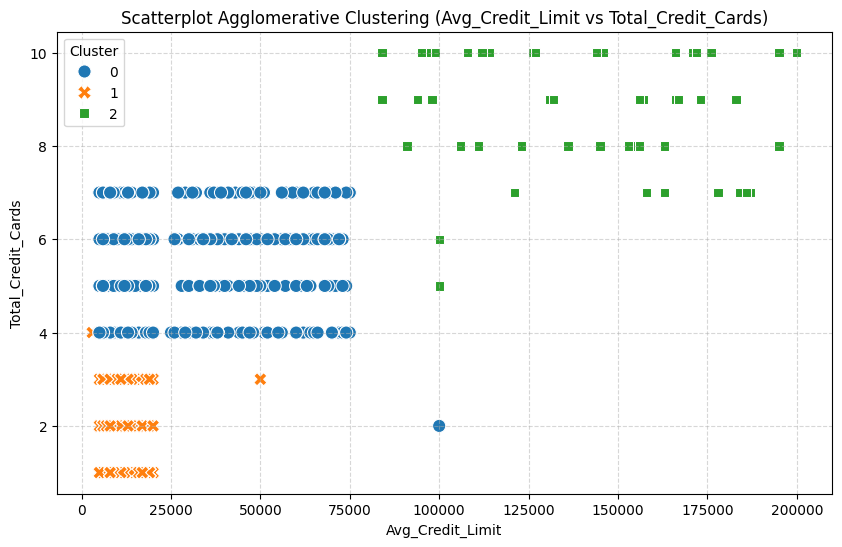

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 1. Memuat dataset dan memilih seluruh variabel yang relevan
df = pd.read_csv('CC_Customer_Dataset.csv')
features = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]
X = df[features]

# 2. Standardisasi data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Membuat model Agglomerative Clustering (k=3, Ward linkage)
agg_model = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df['Cluster'] = agg_model.fit_predict(X_scaled)

# 4. Menghitung Silhouette Score dan Davies-Bouldin Index (DBI)
sil_score = silhouette_score(X_scaled, df['Cluster'])
dbi_score = davies_bouldin_score(X_scaled, df['Cluster'])

print(f"Silhouette Score : {sil_score:.4f}")
print(f"DBI Score        : {dbi_score:.4f}")

# 5. Visualisasi Scatterplot (Avg_Credit_Limit vs Total_Credit_Cards)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='Cluster',
    style='Cluster',
    palette=['#1f77b4', '#ff7f0e', '#2ca02c'],
    s=90
)
plt.title('Scatterplot Agglomerative Clustering (Avg_Credit_Limit vs Total_Credit_Cards)')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()